In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Atur tampilan grafik agar rapi
sns.set_theme(style="whitegrid")

# 1. Membaca dataset BMKG
df = pd.read_csv('BMKG_Earthquake_Catalog.csv')
print("Ukuran data mentah (baris, kolom):", df.shape)

# 2. Hapus kolom artefak kosong ('Unnamed: 2') dan nomor urut ('No')
df_clean = df.drop(columns=['Unnamed: 2', 'No']).copy()

# 3. Konversi kolom tanggal & ekstrak tahun
df_clean['Date'] = pd.to_datetime(df_clean['Date'], format='%d-%b-%Y')
df_clean['Tahun'] = df_clean['Date'].dt.year

# 4. Membuat 5 kategori magnitudo untuk target Random Forest
bins = [0, 3.0, 4.0, 5.0, 6.0, 10.0]
labels = ['Mikro (<3.0)', 'Minor (3.0-3.9)', 'Ringan (4.0-4.9)', 'Sedang (5.0-5.9)', 'Kuat (>=6.0)']
df_clean['Kategori_Magnitudo'] = pd.cut(
    df_clean['Magnitude'], bins=bins, labels=labels, right=False
)

print("Ukuran data setelah pembersihan kolom:", df_clean.shape)
display(df_clean.head())

Ukuran data mentah (baris, kolom): (217807, 12)
Ukuran data setelah pembersihan kolom: (217807, 12)


,Event ID,Date,Time (UTC),Latitude,Longitude,Magnitude,Mag Type,Depth (km),Source,Source Event ID,Tahun,Kategori_Magnitudo
0,BMKG-19980109094543-001,1998-01-09,09:45:43,-5.39,126.17,4.1,-,390,RC_09,-,1998,Ringan (4.0-4.9)
1,BMKG-19980112080550-001,1998-01-12,08:05:50,-3.04,128.36,4.4,-,100,RC_09,-,1998,Ringan (4.0-4.9)
2,BMKG-19980118120317-001,1998-01-18,12:03:17,-2.65,132.13,4.8,-,32,RC_09,-,1998,Ringan (4.0-4.9)
3,BMKG-19980129150524-001,1998-01-29,15:05:24,6.76,127.28,3.8,mb,33,RC_04,-,1998,Minor (3.0-3.9)
4,BMKG-19980205061524-001,1998-02-05,06:15:24,6.88,127.22,4.3,mb,33,RC_04,-,1998,Ringan (4.0-4.9)


In [2]:
# 1. Cek data kosong & duplikat
print("=== CEK DATA KOSONG & DUPLIKAT ===")
print(df_clean.isnull().sum())
print("Jumlah baris duplikat:", df_clean.duplicated().sum())

# 2. Statistik deskriptif fitur numerik
print("\n=== STATISTIK DESKRIPTIF ===")
display(df_clean[['Latitude', 'Longitude', 'Depth (km)', 'Magnitude']].describe().round(2))

# 3. Deteksi Outlier metode IQR
print("\n=== DETEKSI OUTLIER (METODE IQR) ===")
for col in ['Latitude', 'Longitude', 'Depth (km)', 'Magnitude']:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f"{col:12s} | Batas: [{lower:6.2f}, {upper:6.2f}] | Outlier: {n_out:6d} ({n_out/len(df_clean)*100:.2f}%)")

# 4. Tabel Distribusi 5 Kelas Magnitudo
print("\n=== DISTRIBUSI 5 KATEGORI MAGNITUDO ===")
dist = df_clean['Kategori_Magnitudo'].value_counts().reindex(labels)
dist_tabel = pd.DataFrame({
    'Kategori': labels,
    'Jumlah_Data': dist.values,
    'Persentase (%)': (dist.values / len(df_clean) * 100).round(2)
})
display(dist_tabel)

=== CEK DATA KOSONG & DUPLIKAT ===
Event ID              0
Date                  0
Time (UTC)            0
Latitude              0
Longitude             0
Magnitude             0
Mag Type              0
Depth (km)            0
Source                0
Source Event ID       0
Tahun                 0
Kategori_Magnitudo    0
dtype: int64
Jumlah baris duplikat: 0

=== STATISTIK DESKRIPTIF ===


,Latitude,Longitude,Depth (km),Magnitude
count,217807.00,217807.00,217807.00,217807.00
mean,-4.07,118.94,43.24,3.15
std,4.25,11.12,74.94,0.86
min,-14.96,94.00,1.00,0.20
25%,-8.16,110.82,10.00,2.50
50%,-3.62,120.27,14.00,3.00
75%,-0.81,127.07,39.00,3.70
max,7.00,142.00,798.00,7.90



=== DETEKSI OUTLIER (METODE IQR) ===
Latitude     | Batas: [-19.18,  10.21] | Outlier:      0 (0.00%)
Longitude    | Batas: [ 86.44, 151.44] | Outlier:      0 (0.00%)
Depth (km)   | Batas: [-33.50,  82.50] | Outlier:  33331 (15.30%)
Magnitude    | Batas: [  0.70,   5.50] | Outlier:   1112 (0.51%)

=== DISTRIBUSI 5 KATEGORI MAGNITUDO ===


,Kategori,Jumlah_Data,Persentase (%)
0,Mikro (<3.0),99827,45.83
1,Minor (3.0-3.9),76503,35.12
2,Ringan (4.0-4.9),36700,16.85
3,Sedang (5.0-5.9),4344,1.99
4,Kuat (>=6.0),433,0.20


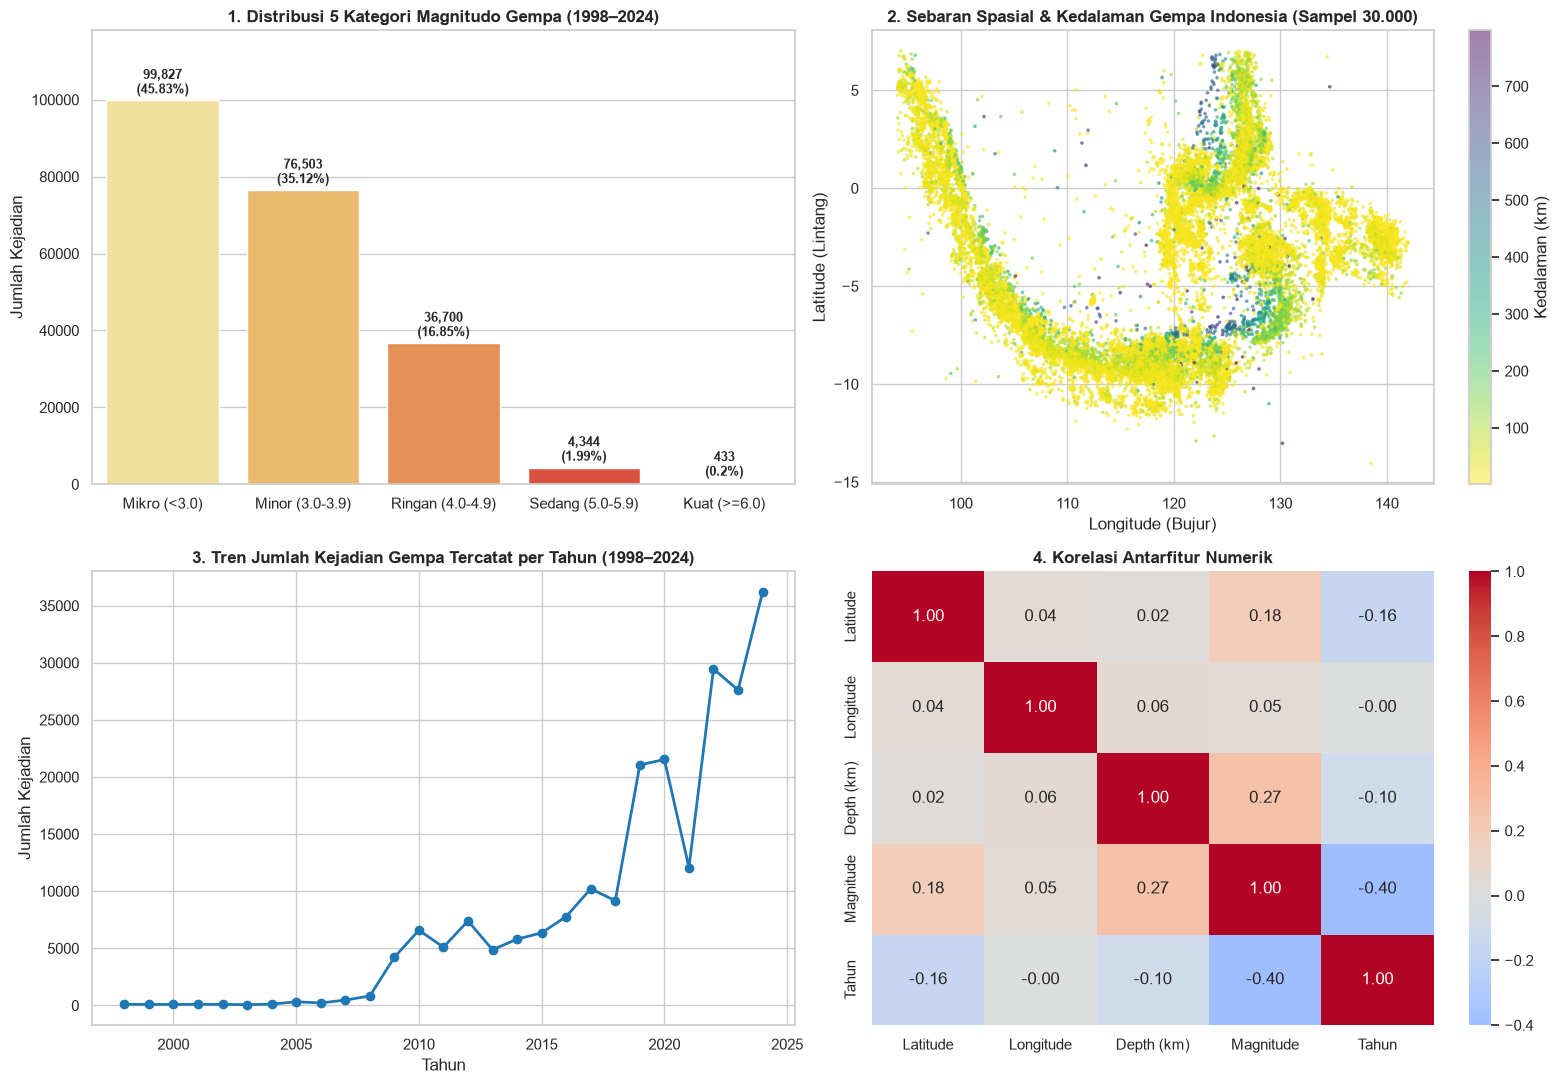

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Grafik 1: Distribusi 5 Kategori Magnitudo (Wajib ada untuk cek ketimpangan kelas)
sns.barplot(
    data=dist_tabel, x='Kategori', y='Jumlah_Data',
    palette='YlOrRd', ax=axes[0, 0], hue='Kategori', legend=False
)
axes[0, 0].set_title('1. Distribusi 5 Kategori Magnitudo Gempa (1998–2024)', fontweight='bold')
axes[0, 0].set_ylabel('Jumlah Kejadian')
axes[0, 0].set_xlabel('')
for idx, row in dist_tabel.iterrows():
    axes[0, 0].text(
        idx, row['Jumlah_Data'] + 1800,
        f"{row['Jumlah_Data']:,}\n({row['Persentase (%)']}%)",
        ha='center', fontsize=9, fontweight='bold'
    )
axes[0, 0].set_ylim(0, 118000)

# Grafik 2: Peta Sebaran Spasial Episenter Gempa Indonesia
sample_df = df_clean.sample(n=30000, random_state=42)  # Sampel 30 ribu titik agar render cepat
sc = axes[0, 1].scatter(
    sample_df['Longitude'], sample_df['Latitude'],
    c=sample_df['Depth (km)'], cmap='viridis_r', s=3, alpha=0.5
)
plt.colorbar(sc, ax=axes[0, 1], label='Kedalaman (km)')
axes[0, 1].set_title('2. Sebaran Spasial & Kedalaman Gempa Indonesia (Sampel 30.000)', fontweight='bold')
axes[0, 1].set_xlabel('Longitude (Bujur)')
axes[0, 1].set_ylabel('Latitude (Lintang)')

# Grafik 3: Tren Jumlah Kejadian Gempa per Tahun (1998–2024)
yearly = df_clean['Tahun'].value_counts().sort_index()
axes[1, 0].plot(yearly.index, yearly.values, marker='o', color='#1f77b4', linewidth=2)
axes[1, 0].set_title('3. Tren Jumlah Kejadian Gempa Tercatat per Tahun (1998–2024)', fontweight='bold')
axes[1, 0].set_xlabel('Tahun')
axes[1, 0].set_ylabel('Jumlah Kejadian')

# Grafik 4: Heatmap Korelasi Fitur Numerik
corr = df_clean[['Latitude', 'Longitude', 'Depth (km)', 'Magnitude', 'Tahun']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 1])
axes[1, 1].set_title('4. Korelasi Antarfitur Numerik', fontweight='bold')

plt.tight_layout()
plt.show()

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# 1. Standarisasi fitur spasial & kedalaman untuk klasterisasi
X_clust = df_clean[['Latitude', 'Longitude', 'Depth (km)']].copy()
scaler_c = StandardScaler()
X_clust_scaled = scaler_c.fit_transform(X_clust)

# 2. Uji jumlah klaster K-Means (k = 2 s.d. 6) untuk Bab 4.3 (Asumsi Model)
print("=== EVALUASI JUMLAH KLASTER K-MEANS ===")
inertias, sil_scores = [], []
k_range = range(2, 7)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_clust_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_clust_scaled, lbl, sample_size=10000, random_state=42)
    sil_scores.append(sil)
    print(f"k = {k} | Inertia = {km.inertia_:,.0f} | Silhouette Score = {sil:.4f}")

# 3. Simpan hasil klaster K-Means terbaik (k=4) sebagai fitur tambahan zona seismik
kmeans_best = KMeans(n_clusters=4, random_state=42, n_init=10)
df_clean['Cluster_KMeans'] = kmeans_best.fit_predict(X_clust_scaled)

# 4. Bandingkan dengan DBSCAN (pada sampel 30.000 data agar R   AM & waktu tetap ringan)
idx_sample = np.random.RandomState(42).choice(len(X_clust_scaled), size=30000, replace=False)
X_db = X_clust_scaled[idx_sample]
dbscan = DBSCAN(eps=0.35, min_samples=30, n_jobs=-1)
db_labels = dbscan.fit_predict(X_db)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise_db = list(db_labels).count(-1)
mask_valid = db_labels != -1
sil_db = silhouette_score(X_db[mask_valid], db_labels[mask_valid], sample_size=10000, random_state=42)

print(f"\n=== PERBANDINGAN KLASTERISASI ===")
print(f"K-Means (k=4) -> Klaster: 4 | Noise: 0.00% | Silhouette Score: {sil_scores[2]:.4f}")
print(f"DBSCAN        -> Klaster: {n_clusters_db} | Noise: {n_noise_db/len(db_labels)*100:.2f}% | Silhouette Score: {sil_db:.4f}")

=== EVALUASI JUMLAH KLASTER K-MEANS ===
k = 2 | Inertia = 464,190 | Silhouette Score = 0.3789
k = 3 | Inertia = 336,186 | Silhouette Score = 0.4462
k = 4 | Inertia = 217,549 | Silhouette Score = 0.4823
k = 5 | Inertia = 170,582 | Silhouette Score = 0.4984
k = 6 | Inertia = 142,754 | Silhouette Score = 0.4479

=== PERBANDINGAN KLASTERISASI ===
K-Means (k=4) -> Klaster: 4 | Noise: 0.00% | Silhouette Score: 0.4823
DBSCAN        -> Klaster: 4 | Noise: 2.01% | Silhouette Score: 0.3147


In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# 1. Ekstraksi fitur waktu (Bulan & Jam UTC)
df_clean['Bulan'] = df_clean['Date'].dt.month
df_clean['Jam'] = pd.to_datetime(df_clean['Time (UTC)'], format='%H:%M:%S', errors='coerce').dt.hour.fillna(0).astype(int)

# 2. Tentukan fitur (X) dan target 5 kelas (y) — tanpa Magnitude agar tidak bocor
num_cols = ['Latitude', 'Longitude', 'Depth (km)', 'Tahun', 'Bulan', 'Jam']
cat_cols = ['Source', 'Mag Type', 'Cluster_KMeans']

X = df_clean[num_cols + cat_cols]
y = df_clean['Kategori_Magnitudo']

# 3. Split data 80:20 secara Stratified (menjaga proporsi kelas kecil tetap sama)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Jumlah Data Latih: {len(X_train):,} | Data Uji: {len(X_test):,}")

# 4. Pipeline Preprocessing (fit hanya pada data latih agar tidak bocor)
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# 5. Latih 1 Model Baseline + 2 Model Alternatif (sesuai ketentuan Bab 4.1)
models = {
    'Logistic Regression (Baseline)': LogisticRegression(max_iter=500, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=15, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=18, class_weight='balanced_subsample', random_state=42, n_jobs=-1
    )
}

# Sampel stratified 30.000 baris khusus hitung 3-Fold CV agar laptop tidak berat
X_cv, _, y_cv, _ = train_test_split(X_train, y_train, train_size=30000, random_state=42, stratify=y_train)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

hasil_model = []
for nama, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    f1_mac = f1_score(y_test, y_pred, average='macro')
    f1_wei = f1_score(y_test, y_pred, average='weighted')
    cv_f1 = cross_val_score(pipe, X_cv, y_cv, cv=cv, scoring='f1_macro', n_jobs=-1).mean()
    
    hasil_model.append({
        'Model': nama,
        'Accuracy': round(acc, 4),
        'Macro F1-Score': round(f1_mac, 4),
        'Weighted F1-Score': round(f1_wei, 4),
        'Rata-rata CV (Macro F1)': round(cv_f1, 4)
    })
    
    if nama == 'Random Forest':
        rf_pipe = pipe
        rf_pred = y_pred

print("\n=== TABEL PERBANDINGAN MODEL KLASIFIKASI (BAB 5.2) ===")
display(pd.DataFrame(hasil_model))

Jumlah Data Latih: 174,245 | Data Uji: 43,562

=== TABEL PERBANDINGAN MODEL KLASIFIKASI (BAB 5.2) ===


,Model,Accuracy,Macro F1-Score,Weighted F1-Score,Rata-rata CV (Macro F1)
0,Logistic Regression (Baseline),0.5368,0.3598,0.5555,0.3608
1,Decision Tree,0.6370,0.4407,0.6494,0.4152
2,Random Forest,0.6811,0.5143,0.6846,0.4731


=== CLASSIFICATION REPORT RANDOM FOREST ===
                  precision    recall  f1-score   support

    Mikro (<3.0)     0.8282    0.7579    0.7915     19966
 Minor (3.0-3.9)     0.5834    0.6461    0.6131     15301
Ringan (4.0-4.9)     0.5767    0.5700    0.5733      7340
Sedang (5.0-5.9)     0.4438    0.5270    0.4819       869
    Kuat (>=6.0)     0.1404    0.0930    0.1119        86

        accuracy                         0.6811     43562
       macro avg     0.5145    0.5188    0.5143     43562
    weighted avg     0.6908    0.6811    0.6846     43562

=== TABEL TP, TN, FP, FN & F1-SCORE PER KELAS ===


,Kategori Magnitudo,TP,TN,FP,FN,Precision,Recall,F1-Score
0,Mikro (<3.0),15132,20456,3140,4834,0.8282,0.7579,0.7915
1,Minor (3.0-3.9),9886,21201,7060,5415,0.5834,0.6461,0.6131
2,Ringan (4.0-4.9),4184,33151,3071,3156,0.5767,0.5700,0.5733
3,Sedang (5.0-5.9),458,42119,574,411,0.4438,0.5270,0.4819
4,Kuat (>=6.0),8,43427,49,78,0.1404,0.0930,0.1119



>> KELAS PALING MUDAH DIPREDIKSI : Mikro (<3.0) (F1-Score = 0.7915, TP = 15,132, TN = 20,456)
>> KELAS PALING SULIT DIPREDIKSI : Kuat (>=6.0) (F1-Score = 0.1119, TP = 8, TN = 43,427)


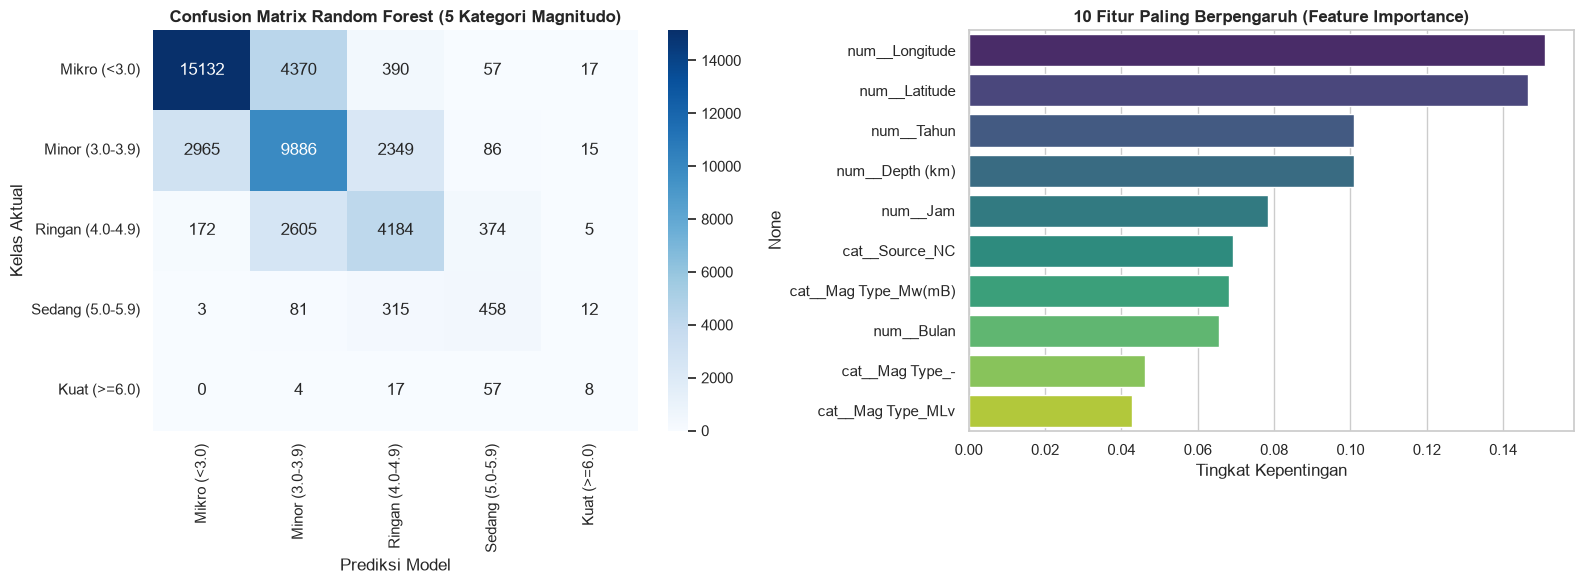

In [6]:
from sklearn.metrics import confusion_matrix, classification_report

# 1. Classification Report lengkap per kelas
print("=== CLASSIFICATION REPORT RANDOM FOREST ===")
print(classification_report(y_test, rf_pred, labels=labels, target_names=labels, digits=4))

# 2. Hitung TP, TN, FP, FN, dan F1-Score untuk masing-masing dari 5 kelas
cm = confusion_matrix(y_test, rf_pred, labels=labels)
total_uji = cm.sum()

detail_kelas = []
for i, kelas in enumerate(labels):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = total_uji - (tp + fn + fp)
    
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    
    detail_kelas.append({
        'Kategori Magnitudo': kelas,
        'TP': tp,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

df_eval_kelas = pd.DataFrame(detail_kelas)
print("=== TABEL TP, TN, FP, FN & F1-SCORE PER KELAS ===")
display(df_eval_kelas)

# 3. Identifikasi otomatis kelas paling mudah & paling sulit diprediksi
termudah = df_eval_kelas.loc[df_eval_kelas['F1-Score'].idxmax()]
tersulit = df_eval_kelas.loc[df_eval_kelas['F1-Score'].idxmin()]

print(f"\n>> KELAS PALING MUDAH DIPREDIKSI : {termudah['Kategori Magnitudo']} (F1-Score = {termudah['F1-Score']:.4f}, TP = {termudah['TP']:,}, TN = {termudah['TN']:,})")
print(f">> KELAS PALING SULIT DIPREDIKSI : {tersulit['Kategori Magnitudo']} (F1-Score = {tersulit['F1-Score']:.4f}, TP = {tersulit['TP']:,}, TN = {tersulit['TN']:,})")

# 4. Visualisasi Confusion Matrix & Feature Importance (untuk Bab 5.3)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=labels, yticklabels=labels, ax=axes[0]
)
axes[0].set_title('Confusion Matrix Random Forest (5 Kategori Magnitudo)', fontweight='bold')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Kelas Aktual')

# Ambil 10 fitur paling berpengaruh
feature_names = rf_pipe.named_steps['prep'].get_feature_names_out()
importances = rf_pipe.named_steps['model'].feature_importances_
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(10)

sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='viridis', ax=axes[1], hue=feat_imp.index, legend=False)
axes[1].set_title('10 Fitur Paling Berpengaruh (Feature Importance)', fontweight='bold')
axes[1].set_xlabel('Tingkat Kepentingan')

plt.tight_layout()
plt.show()